In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from carbonfund_experiments import (
    Table,
    validate_config,
    run_experiment,
    load_result,
)

In [2]:
PROJECT = Path(
    "/home/edoardolombardo/Documents/codes/CarbonFund_UL"
)

EXECUTABLE = (
    PROJECT / "build-paper-release" / "carbonfund_experiment"
)

RUN_NAME = "pricing_PE_T20_four_estimators"

OUTPUT_DIRECTORY = PROJECT / "results" / "notebooks" / RUN_NAME

OVERWRITE_EXISTING = False
SAVE_PLOTS = True
SHOW_PROGRESS = True

SCIENTIFIC_DIGITS = 4
FIXED_DIGITS = 4

assert EXECUTABLE.is_file(), (
    f"Executable not found: {EXECUTABLE}"
)

In [3]:
market = {
    "risk_free_rate": 0.05,

    "expected_returns": [
        0.25,
        0.15,
        0.10,
        0.08,
    ],

    "volatilities": [
        0.30,
        0.25,
        0.20,
        0.16,
    ],

    "correlations": [
        [1.00, 0.44, 0.39, 0.32],
        [0.44, 1.00, 0.30, 0.33],
        [0.39, 0.30, 1.00, 0.31],
        [0.32, 0.33, 0.31, 1.00],
    ],
}

In [4]:
carbon = {
    "model": "CIR",

    "initial": [
        5000.0,
        4000.0,
        3000.0,
        1000.0,
    ],

    "long_run_mean": [
        2500.0,
        2000.0,
        1500.0,
        500.0,
    ],

    "mean_reversion": [
        0.05,
        0.05,
        0.05,
        0.05,
    ],

    "volatility": [
        3.0,
        3.0,
        3.0,
        3.0,
    ],
}

In [5]:
fund = {
    "risk_aversion": 1.0,
    "carbon_penalty": 0.0025,
}

In [6]:
CONTRACT_TYPE = "PE"

contract = {
    "fund_value": 1.0,

    "maturity": 20.0,

    "minimum_guarantee": 1.0,
    "maximum_guarantee": 1.0,

    "minimum_guarantee_growth_rate": 0.05,
    "maximum_guarantee_growth_rate": 0.50,

    "endowment_death_benefit_fraction": 1.0,
}

In [7]:
mortality = {
    "xi": 0.0041959,
    "m": 79.6921211,
    "b": 11.5818911,
}

In [8]:
population = [
    {
        "type": CONTRACT_TYPE,
        "age": 60.0,
        "notional": 1.0,
    },
]

In [9]:
pricing = {
    "contract": CONTRACT_TYPE,

    "paths": 100_000,
    "intervals": 100,

    "configurations": [
        "standard",
        "standard_antithetic",
        "conditioned",
        "conditioned_antithetic",
    ],

    "repetitions": 3,

    "carbon_seed": 20261015,
    "financial_seed": 20261016,
}

In [11]:
analysis = {
    "normalization": "aggregate",

    "confidence_level": 0.95,

    "comparison_family_size": 12,

    "quantiles": [],                 #not used in pricing analysis
    "expected_shortfall_levels": [], #not used in pricing analysis

    "bins": 70,
    "zoom": None,
    "plot_range": None,

    "figure_formats": [
        "png",
        "pdf",
    ],

    "dpi": 180,

    "title": "Pure endowment: four estimators, T = 20",
}

In [12]:
config = {
    "schema_version": 1,

    "experiment": "pricing",

    "market": market,
    "carbon": carbon,
    "fund": fund,
    "contract": contract,
    "mortality": mortality,
    "population": population,

    "pricing": pricing,

    "analysis": analysis,

    "notes": (
        "Explicit notebook inputs. "
        "Paper benchmark calibration; "
        "corrected xi and exponent age+t-m."
    ),
}

validate_config(config)

print(json.dumps(config, indent=2))

{
  "schema_version": 1,
  "experiment": "pricing",
  "market": {
    "risk_free_rate": 0.05,
    "expected_returns": [
      0.25,
      0.15,
      0.1,
      0.08
    ],
    "volatilities": [
      0.3,
      0.25,
      0.2,
      0.16
    ],
    "correlations": [
      [
        1.0,
        0.44,
        0.39,
        0.32
      ],
      [
        0.44,
        1.0,
        0.3,
        0.33
      ],
      [
        0.39,
        0.3,
        1.0,
        0.31
      ],
      [
        0.32,
        0.33,
        0.31,
        1.0
      ]
    ]
  },
  "carbon": {
    "model": "CIR",
    "initial": [
      5000.0,
      4000.0,
      3000.0,
      1000.0
    ],
    "long_run_mean": [
      2500.0,
      2000.0,
      1500.0,
      500.0
    ],
    "mean_reversion": [
      0.05,
      0.05,
      0.05,
      0.05
    ],
    "volatility": [
      3.0,
      3.0,
      3.0,
      3.0
    ]
  },
  "fund": {
    "risk_aversion": 1.0,
    "carbon_penalty": 0.0025
  },
  "contract": {
  

In [13]:
result = run_experiment(
    config=config,
    output_dir=OUTPUT_DIRECTORY,
    binary=EXECUTABLE,
    overwrite=OVERWRITE_EXISTING,
    plots=SAVE_PLOTS,
    progress=SHOW_PROGRESS,
)

print("Results saved in:", result.directory)

Pricing repetitions completed: 1/3
Pricing repetitions completed: 2/3
Pricing repetitions completed: 3/3
Saved experiment to /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/notebooks/pricing_PE_T20_four_estimators
Results saved in: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/notebooks/pricing_PE_T20_four_estimators


In [14]:
def formatted_table(rows):
    formatted = []

    for row in rows:
        output = {}

        for key, value in row.items():
            if isinstance(value, float):

                if not math.isfinite(value):
                    output[key] = ""

                elif key == "variance_reduction_percent":
                    output[key] = (
                        f"{value:.{FIXED_DIGITS}f}%"
                    )

                elif key == "cpu_seconds":
                    output[key] = (
                        f"{value:.{FIXED_DIGITS}f}"
                    )

                else:
                    output[key] = (
                        f"{value:.{SCIENTIFIC_DIGITS}e}"
                    )

            else:
                output[key] = value

        formatted.append(output)

    return Table(formatted)

In [15]:
summary = result.summary()

columns = [
    "configuration",
    "mean",
    "sample_variance",
    "standard_deviation",
    "variance_of_mean",
    "effective_variance",
    "standard_error",
    "variance_reduction_percent",
    "ci_low",
    "ci_high",
    "cpu_seconds",
]

for quantity in ("price", "delta"):

    rows = [
        {
            column: row[column]
            for column in columns
        }
        for row in summary
        if row["quantity"] == quantity
    ]

    print(quantity.upper())

    display(formatted_table(rows))

PRICE


configuration,mean,sample_variance,standard_deviation,variance_of_mean,effective_variance,standard_error,variance_reduction_percent,ci_low,ci_high,cpu_seconds
standard,4.8359e-01,3.6460e-02,1.9094e-01,3.6460e-07,3.6460e-02,6.0382e-04,0.0000%,4.8241e-01,4.8477e-01,0.7189
standard_antithetic,4.8317e-01,1.3602e-02,1.1663e-01,2.7204e-07,2.7204e-02,5.2157e-04,25.3871%,4.8215e-01,4.8419e-01,0.5601
conditioned,4.8406e-01,2.0306e-05,4.5063e-03,2.0306e-10,2.0306e-05,1.4250e-05,99.9443%,4.8403e-01,4.8409e-01,0.7409
conditioned_antithetic,4.8403e-01,4.9327e-07,7.0233e-04,9.8655e-12,9.8655e-07,3.1409e-06,99.9973%,4.8402e-01,4.8404e-01,0.5994


DELTA


configuration,mean,sample_variance,standard_deviation,variance_of_mean,effective_variance,standard_error,variance_reduction_percent,ci_low,ci_high,cpu_seconds
standard,2.4013e-01,1.1643e-01,3.4121e-01,1.1643e-06,1.1643e-01,1.0790e-03,0.0000%,2.3802e-01,2.4225e-01,0.7189
standard_antithetic,2.4141e-01,2.8137e-02,1.6774e-01,5.6273e-07,5.6273e-02,7.5015e-04,51.6667%,2.3994e-01,2.4288e-01,0.5601
conditioned,2.4203e-01,5.0766e-06,2.2531e-03,5.0766e-11,5.0766e-06,7.1250e-06,99.9956%,2.4202e-01,2.4204e-01,0.7409
conditioned_antithetic,2.4201e-01,1.2332e-07,3.5117e-04,2.4664e-12,2.4664e-07,1.5705e-06,99.9998%,2.4201e-01,2.4202e-01,0.5994


In [16]:
count_columns = [
    "configuration",
    "requested_paths",
    "actual_paths",
    "independent_samples",
]

count_rows = [
    {
        column: row[column]
        for column in count_columns
    }
    for row in summary
    if row["quantity"] == "price"
]

display(Table(count_rows))

configuration,requested_paths,actual_paths,independent_samples
standard,100000,100000,100000
standard_antithetic,100000,100000,50000
conditioned,100000,100000,100000
conditioned_antithetic,100000,100000,50000


In [17]:
seed_columns = [
    "repetition",
    "carbon_seed",
    "financial_seed",
]

seed_rows = [
    {
        column: row[column]
        for column in seed_columns
    }
    for row in result.pricing["repetitions"]
    if (
        row["quantity"] == "price"
        and row["configuration"] == "standard"
    )
]

display(Table(seed_rows))

repetition,carbon_seed,financial_seed
0,20261015,20261016
1,4154154545692503677,8099358280037599703
2,8467169762938477137,12714201419439376771


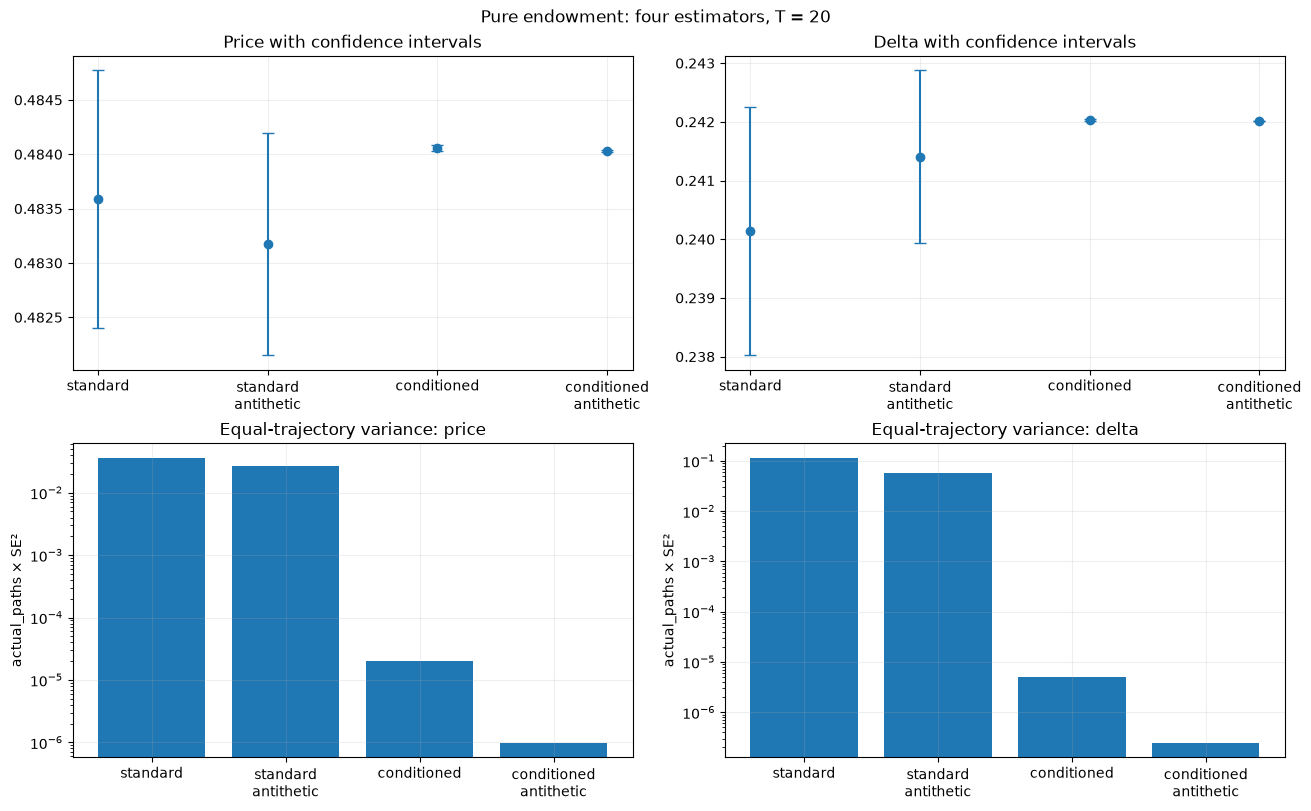

In [20]:
fig = result.plot()

plt.show()